In [2]:
"""
Unit 5: Evolving Your IPD Agent with Genetic Algorithms
========================================================

In Unit 4, you hand-coded agent strategies like Tit-for-Tat.
In Unit 5, you'll use evolution to DISCOVER strategies automatically.

By the end, you'll have an evolved agent saved as a JSON file for the tournament!
"""

# ============================================================================
# SETUP: Import everything from previous units
# ============================================================================

import random
import numpy as np
import json
import matplotlib.pyplot as plt
from agents import Agent, INVEST, UNDERCUT
from game_engine import Game, Tournament

# Import all hand-coded agents from Unit 4
from agents import (
    AlwaysInvestAgent, AlwaysUndercutAgent, TitForTatAgent,
    GrimTriggerAgent, PavlovAgent, TitForTwoTatsAgent,
    GenerousTitForTatAgent, AdaptiveAgent, RandomAgent,
    SuspiciousTitForTatAgent, GradualAgent, HardMajorityAgent,
    SoftMajorityAgent, ProberAgent
)

print("✅ Imports complete!")

✅ Imports complete!


In [3]:

# ============================================================================
# PART 1: THE EVOLVABLE AGENT (PROVIDED - Read but don't modify)
# ============================================================================

class EvolvableAgent(Agent):
    """
    An agent whose strategy is controlled by 6 genes (numbers from 0 to 1).
    
    Think of genes as "strategy dials" you can tune:
    
    Gene[0] - Initial Cooperation (0=hostile start, 1=friendly start)
    Gene[1] - Cooperation Response (if opponent cooperates, how likely to cooperate back?)
    Gene[2] - Defection Response (if opponent defects, how likely to defect back?)
    Gene[3] - Forgiveness (after retaliation, chance to forgive)
    Gene[4] - Memory Length (0=last 1 round, 1=last 10 rounds)
    Gene[5] - Retaliation Threshold (what % of defections triggers retaliation)
    """
    
    def __init__(self, genes=None, name="Evolved Agent"):
        if genes is None:
            # Create random genes if none provided
            genes = [random.random() for _ in range(6)]
        
        self.genes = genes
        super().__init__(name, f"Genes: [{', '.join([f'{g:.2f}' for g in genes])}]")
    
    def choose_action(self) -> bool:
        """Decision logic based on genes - SIMPLIFIED FOR LEARNING"""
        
        # First 3 rounds: use initial cooperation gene
        if self.round_num < 3:
            return random.random() < self.genes[0]
        
        # Calculate memory window (gene[4])
        memory_length = max(1, int(self.genes[4] * 10) + 1)
        recent_history = self.history[-memory_length:]
        
        # Calculate opponent's recent COOPERATION rate (not defection!)
        cooperation_rate = sum(recent_history) / len(recent_history)
        
        # If opponent is mostly cooperating, reciprocate
        if cooperation_rate >= 0.5:
            return random.random() < self.genes[1]  # gene[1] = cooperate response
        
        # If opponent is mostly defecting, retaliate or forgive
        else:
            # Retaliate with probability gene[2]
            if random.random() < self.genes[2]:
                return UNDERCUT
            # Or forgive with probability gene[3]
            elif random.random() < self.genes[3]:
                return INVEST
            else:
                return UNDERCUT


In [16]:

# ============================================================================
# PART 2: DEFINE THE OPPONENT ECOSYSTEM
# ============================================================================

# ============================================================================
# EXPANDED OPPONENT POOL
# ============================================================================

# Full pool of all possible opponents
full_opponent_pool = [
    # Cooperative agents
    AlwaysInvestAgent(),
    TitForTatAgent(),
    GrimTriggerAgent(),
    PavlovAgent(),
    TitForTwoTatsAgent(),
    GenerousTitForTatAgent(),
    AdaptiveAgent(),
    
    # Aggressive agents
    AlwaysUndercutAgent(),
    SuspiciousTitForTatAgent(),
    
    # Sophisticated agents
    GradualAgent(),
    ProberAgent(),
    
    # Majority-based agents
    HardMajorityAgent(),
    SoftMajorityAgent(),
    
    # Random agents with different cooperation levels
    RandomAgent(0.9),
    RandomAgent(0.7),
    RandomAgent(0.5),
    RandomAgent(0.3),
    RandomAgent(0.1),
]

print(f"\n📚 Full opponent library: {len(full_opponent_pool)} agents available")

# For initial evolution, randomly sample opponents
opponent_pool = random.sample(full_opponent_pool, 10)

print(f"🎲 Randomly selected {len(opponent_pool)} opponents for this evolution:")
for i, opp in enumerate(opponent_pool, 1):
    print(f"  {i:2d}. {opp.name:25s} - {opp.description}")
print("="*70)




📚 Full opponent library: 18 agents available
🎲 Randomly selected 10 opponents for this evolution:
   1. Always Invest             - Always invests in market development
   2. Random (0.5)              - Randomly invests 50% of the time
   3. Random (0.3)              - Randomly invests 30% of the time
   4. Grim Trigger              - Invests until betrayed once, then undercuts forever
   5. Gradual                   - Escalates punishment after each betrayal
   6. Tit-for-Two-Tats          - Tolerates one betrayal, retaliates after two
   7. Random (0.9)              - Randomly invests 90% of the time
   8. Generous Tit-for-Tat      - Tit-for-Tat with 10% forgiveness
   9. Hard Majority             - Defects if opponent defects >50% of time
  10. Always Undercut           - Always undercuts competitors


In [17]:

# ============================================================================
# PART 3: GENETIC ALGORITHM FUNCTIONS (YOUR TODO!)
# ============================================================================

def initialize_population(pop_size):
    """
    Create initial population of random agents.
    
    Args:
        pop_size: Number of agents in population
    
    Returns:
        List of EvolvableAgent objects with random genes
    """
    population = []
    for i in range(pop_size):
        agent = EvolvableAgent(name=f"Agent_{i}")
        population.append(agent)
    return population


def evaluate_fitness(agent, opponents, num_rounds=50):
    """
    Measure how good an agent is by playing against all opponents.
    
    Args:
        agent: The EvolvableAgent to evaluate
        opponents: List of opponent agents to play against
        num_rounds: Number of rounds per game
    
    Returns:
        Float: Average score per game (higher is better)
    """
    total_score = 0
    num_games = 0
    
    for opponent in opponents:
        game = Game(agent, opponent, num_rounds=num_rounds)
        score, _ = game.play()
        total_score += score
        num_games += 1
    
    avg_score = total_score / num_games
    return avg_score


def tournament_selection(population, fitnesses, tournament_size=3):
    """
    Select parents using tournament selection.

    Randomly sample contestants and select the highest-fitness agent.
    Repeat until the parent pool matches the population size.
    Copy each winner's genes to protect the original agent.
    """
    if len(population) != len(fitnesses):
        raise ValueError("Each agent must have one fitness score.")

    if not 1 <= tournament_size <= len(population):
        raise ValueError("Tournament size must be between 1 and population size.")

    selected = []

    for _ in range(len(population)):
        # Choose contestants randomly for each tournament.
        contestants_idx = random.sample(
            range(len(population)), tournament_size
        )

        # Select the contestant with the highest fitness.
        best_idx = max(contestants_idx, key=lambda i: fitnesses[i])

        # Copy genes so later changes cannot affect the original.
        winner_genes = population[best_idx].genes.copy()
        selected.append(EvolvableAgent(genes=winner_genes))

    return selected


def crossover_and_mutate(parent1, parent2, mutation_rate=0.15):
    """
    Create a child by combining both parents' genes.
    Mutate individual genes and keep their values between 0 and 1.
    """
    if len(parent1.genes) != len(parent2.genes):
        raise ValueError("Parents must have the same number of genes.")

    if len(parent1.genes) < 2:
        raise ValueError("Crossover requires at least two genes.")

    if not 0.0 <= mutation_rate <= 1.0:
        raise ValueError("Mutation rate must be between 0 and 1.")

    # Choose an internal split so both parents contribute genes.
    crossover_point = random.randint(1, len(parent1.genes) - 1)

    # Slicing and concatenation create a new list for the child.
    child_genes = (parent1.genes[:crossover_point] + parent2.genes[crossover_point:])

    # Each gene has an independent chance of mutation.
    for i in range(len(child_genes)):
        if random.random() < mutation_rate:
            child_genes[i] += random.gauss(0, 0.2)

            # Keep the mutated gene within its valid limits.
            child_genes[i] = max(0.0, min(1.0, child_genes[i]))

    return EvolvableAgent(genes=child_genes)


def evolve(generations=25, pop_size=20, opponents=None, mutation_rate=0.15, elitism=2):
    """
    Evolve agents through fitness-based selection and reproduction.

    Preserve elite agents unchanged, fill the remaining population with offspring, and return a copy of the best agent observed.
    """
    if opponents is None:
        opponents = opponent_pool

    # Check settings before starting evolution.
    if generations < 1:
        raise ValueError("Use at least one generation.")
    if pop_size < 3:
        raise ValueError("Population size must be at least 3.")
    if not 0 <= elitism < pop_size:
        raise ValueError("Elitism must be between 0 and pop_size - 1.")
    if not 0.0 <= mutation_rate <= 1.0:
        raise ValueError("Mutation rate must be between 0 and 1.")
    if not opponents:
        raise ValueError("Provide at least one opponent.")

    print("\n🧬 EVOLUTION STARTING")
    print("=" * 70)
    print(
        f"Population: {pop_size} | Generations: {generations} | "
        f"Mutation: {mutation_rate}"
    )
    print(f"Opponents: {len(opponents)} | Elitism: {elitism}")
    print("=" * 70)

    best_fitness_history = []
    avg_fitness_history = []
    best_observed_history = []

    population = initialize_population(pop_size)

    best_overall_agent = None
    best_overall_fitness = -float("inf")

    for gen in range(generations):
        # 1. Evaluate every agent against the training opponents.
        fitnesses = []
        for agent in population:
            fitness = evaluate_fitness(
                agent, opponents, num_rounds=50
            )
            fitnesses.append(fitness)

        # 2. Record this generation's performance.
        best_idx = max(
            range(len(population)),
            key=lambda i: fitnesses[i]
        )
        best_fitness = fitnesses[best_idx]
        avg_fitness = sum(fitnesses) / len(fitnesses)

        best_fitness_history.append(best_fitness)
        avg_fitness_history.append(avg_fitness)

        # 3. Save an independent copy of the best agent observed.
        if best_fitness > best_overall_fitness:
            best_overall_fitness = best_fitness
            best_overall_agent = EvolvableAgent(
                genes=population[best_idx].genes.copy()
            )

        best_observed_history.append(best_overall_fitness)

        print(
            f"Gen {gen + 1:3d}/{generations}: "
            f"Best={best_fitness:6.2f} | "
            f"Avg={avg_fitness:6.2f} | "
            f"Genes={[f'{g:.2f}' for g in population[best_idx].genes]}"
        )

        # The final evaluated generation needs no offspring.
        if gen == generations - 1:
            break

        # 4. Preserve the highest-fitness agents unchanged.
        sorted_indices = sorted(
            range(len(population)),
            key=lambda i: fitnesses[i],
            reverse=True
        )

        next_population = []
        for elite_idx in sorted_indices[:elitism]:
            elite_genes = population[elite_idx].genes.copy()
            next_population.append(
                EvolvableAgent(genes=elite_genes)
            )

        # 5. Select a parent pool using fitness-based tournaments.
        selected = tournament_selection(
            population, fitnesses, tournament_size=3
        )

        # 6. Fill remaining spaces with inherited, mutated genes.
        while len(next_population) < pop_size:
            parent1, parent2 = random.sample(selected, 2)
            child = crossover_and_mutate(
                parent1, parent2, mutation_rate
            )
            next_population.append(child)

        # Use the new population in the next generation.
        population = next_population

    print("\n" + "=" * 70)
    print("✅ EVOLUTION COMPLETE!")
    print(f"🏆 Best observed training fitness: {best_overall_fitness:.2f}")
    print("=" * 70)

    # Show current performance separately from the historical record.
    generation_numbers = range(1, generations + 1)

    plt.figure(figsize=(10, 6))
    plt.plot(
        generation_numbers, best_fitness_history,
        label="Generation Best", color="green",
        linewidth=2, marker="o"
    )
    plt.plot(
        generation_numbers, avg_fitness_history,
        label="Generation Average", color="blue",
        linewidth=2, marker="s", alpha=0.7
    )
    plt.plot(
        generation_numbers, best_observed_history,
        label="Best Observed So Far", color="orange",
        linewidth=2, linestyle="--"
    )
    plt.xlabel("Generation", fontsize=12)
    plt.ylabel("Fitness (Average Score per Game)", fontsize=12)
    plt.title("Evolution Progress", fontsize=14, fontweight="bold")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

    return best_overall_agent




🚀 TIME TO EVOLVE YOUR AGENT!

🧬 EVOLUTION STARTING
Population: 20 | Generations: 250 | Mutation: 0.15
Opponents: 10 | Elitism: 2
Gen   1/250: Best=121.10 | Avg=113.70 | Genes=['0.22', '0.98', '0.13', '0.04', '0.69', '0.70']
Gen   2/250: Best=128.50 | Avg=115.15 | Genes=['0.96', '0.97', '0.24', '0.04', '0.73', '0.55']
Gen   3/250: Best=129.30 | Avg=120.05 | Genes=['0.96', '0.97', '0.24', '0.04', '0.73', '0.42']
Gen   4/250: Best=129.40 | Avg=122.83 | Genes=['0.94', '1.00', '0.24', '0.00', '0.73', '0.58']
Gen   5/250: Best=129.40 | Avg=123.87 | Genes=['1.00', '1.00', '0.24', '0.00', '0.45', '0.04']
Gen   6/250: Best=131.10 | Avg=125.75 | Genes=['0.83', '0.57', '0.57', '0.04', '0.74', '0.58']
Gen   7/250: Best=130.30 | Avg=124.30 | Genes=['1.00', '1.00', '0.24', '0.04', '0.88', '0.58']
Gen   8/250: Best=130.80 | Avg=127.42 | Genes=['0.86', '1.00', '0.00', '0.00', '0.45', '0.04']
Gen   9/250: Best=131.80 | Avg=128.16 | Genes=['1.00', '1.00', '0.12', '0.00', '0.45', '0.04']
Gen  10/250: Be

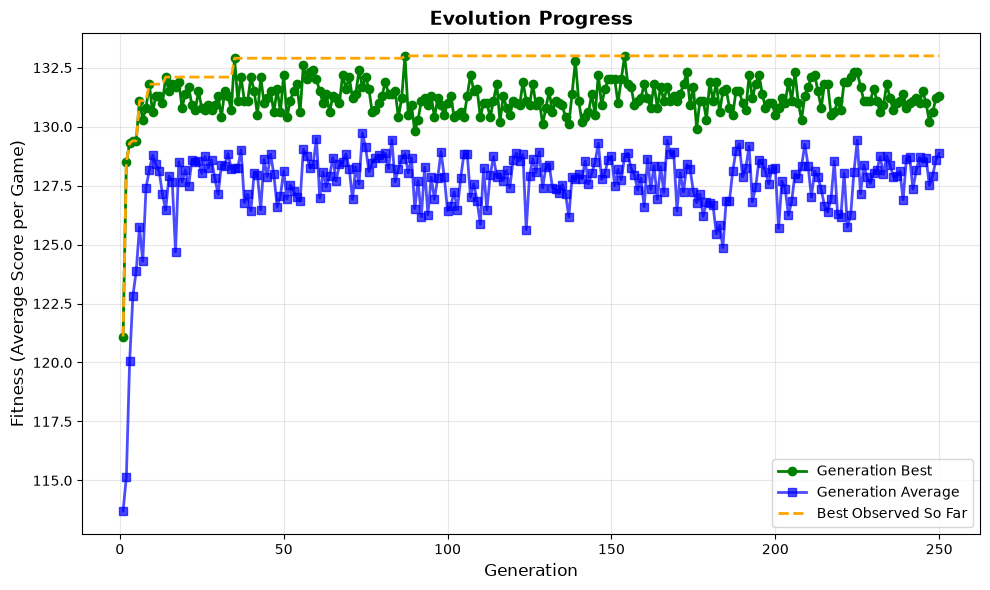


🎉 Your evolved agent's final genes:
   [1.0, 1.0, 1.0, 0.0, 1.0, 0.8050167465242333]


In [20]:

# ============================================================================
# PART 4: RUN EVOLUTION! 
# ============================================================================

print("\n" + "="*70)
print("🚀 TIME TO EVOLVE YOUR AGENT!")
print("="*70)

# TODO: Experiment with these parameters to find the best agent!
my_evolved_agent = evolve(
    generations=250,       # Try: 50, 100, 250
    pop_size=20,         # Try: 15, 20, 30
    opponents=opponent_pool,
    mutation_rate=0.15,  # Try: 0.1, 0.15, 0.2
    elitism=2            # Keep top 2 agents each generation
)

print(f"\n🎉 Your evolved agent's final genes:")
print(f"   {my_evolved_agent.genes}")



In [21]:

# ============================================================================
# PART 5: TEST YOUR AGENT
# ============================================================================

print("\n" + "="*70)
print("⚔️  TESTING YOUR AGENT AGAINST HAND-CODED OPPONENTS")
print("="*70 + "\n")

wins = 0
losses = 0
ties = 0

for opponent in opponent_pool:
    game = Game(my_evolved_agent, opponent, num_rounds=100)
    my_score, opp_score = game.play()
    
    if my_score > opp_score:
        result = "✅ WON"
        wins += 1
    elif my_score < opp_score:
        result = "❌ LOST"
        losses += 1
    else:
        result = "🤝 TIED"
        ties += 1
    
    print(f"vs {opponent.name:25s}: {my_score:3d} - {opp_score:3d}  {result}")

print(f"\n📊 Record: {wins} wins, {losses} losses, {ties} ties")
win_rate = wins / len(opponent_pool) * 100
print(f"🎯 Win Rate: {win_rate:.1f}%")




⚔️  TESTING YOUR AGENT AGAINST HAND-CODED OPPONENTS

vs Always Invest            : 300 - 300  🤝 TIED
vs Random (0.5)             : 235 - 210  ✅ WON
vs Random (0.3)             : 213 - 153  ✅ WON
vs Grim Trigger             : 300 - 300  🤝 TIED
vs Gradual                  : 300 - 300  🤝 TIED
vs Tit-for-Two-Tats         : 300 - 300  🤝 TIED
vs Random (0.9)             : 269 - 314  ❌ LOST
vs Generous Tit-for-Tat     : 300 - 300  🤝 TIED
vs Hard Majority            : 300 - 300  🤝 TIED
vs Always Undercut          :  97 - 112  ❌ LOST

📊 Record: 2 wins, 2 losses, 6 ties
🎯 Win Rate: 20.0%


# Unit 5 Part 2: Benchmark Analysis

**After running your initial evolution and benchmark tests, answer these questions.**

---

## Performance Summary

Fill in your benchmark results:

| Opponent | Result (W/L/T) | Your Score | Opp Score |
|----------|----------------|------------|-----------|
| Always Invest |T |300 |300 |
| Always Undercut | L|97 |112 |
| Hard Majority |T |300 |300 |
| Grim Trigger |T |300 |300 |
| Gradual |T |300 |300 |
| Tit-for-Two-Tats |T |300 |300 |
| Generous Tit-for-Tat |T |300 |300 |
| Random (0.5) |W |235 |210 |
| Random (0.9) |L |269 |314 |
| Random (0.3) |W |213 |153 |
| **Total** | 2 W / 2 L / 6 T |2614 |2589 |

---

## Analysis Questions

### 1. What was your agent's worst loss (greatest point differential) and why?
My agent’s worst loss was against Random (0.9), scoring 269 points against 314—a difference of 45 points. My evolved agent invests during its first three rounds and then continues investing whenever at least half of the opponent’s recent actions were investments, using a memory window of up to 11 rounds. Because Random (0.9) invests frequently, my agent generally has a reason to keep cooperating, but the opponent’s occasional undercuts can earn it five points while my agent receives zero. This explains how a mostly cooperative opponent can still finish ahead without deliberately planning to exploit my agent. The loss reveals a trade-off: tolerating occasional undercuts can preserve cooperation, but it can also give the opponent a scoring advantage.

---

### 2. What pattern do you see in wins vs. losses?

My agent earned six 300–300 ties, including against Grim Trigger, Gradual, and Hard Majority, showing that it could maintain cooperation with opponents whose behavior responds to its actions. It beat Random (0.5) by 235–210 and Random (0.3) by 213–153, which is consistent with its ability to switch to undercutting when recent investment becomes less frequent. Its two losses exposed different weaknesses: Random (0.9) benefited from occasional undercuts, while Always Undercut benefited from my agent’s cooperative opening before it became defensive. Although the win rate was only 20%, the six mutually cooperative matches produced strong scores, so judging performance only by wins would overlook much of what the agent did successfully.

---

### 3. What would make an agent more competitive?

I would use the currently unused retaliation-threshold gene to let evolution adjust how much undercutting the agent tolerates, instead of forcing every evolved strategy to use the same 50% cutoff. I would also shorten the unconditional three-round opening and respond sooner to consecutive undercuts, reducing the early losses against opponents such as Always Undercut. Against mostly cooperative opponents, I would make retaliation and forgiveness depend on whether undercutting persists and whether my own previous action may have provoked it, aiming to protect earnings without disrupting productive cooperation. I would compare the improved agent’s average scores against this same opponent pool over repeated matches, then evaluate additional opponents to check whether the improvements extend beyond its training environment.

---

**Next:** Proceed to Part 3 to implement your improvements!

In [22]:

# ============================================================================
# PART 6: IMPROVE YOUR AGENT'S ACTION TAKING STRATEGY
# ============================================================================

class ImprovedEvolvableAgent(Agent):
    """
    Six evolved genes control the strategy:

    Gene 0: Probability of investing on the first round
    Gene 1: Probability of reciprocating cooperation
    Gene 2: Strength of retaliation when defensive behavior is needed
    Gene 3: Willingness to forgive an otherwise cooperative opponent
    Gene 4: Memory window, ranging from 2 to 20 actions
    Gene 5: Tolerated defection rate, ranging from 10% to 60%

    The decision structure is hand-coded; evolution tunes its settings.
    """

    def __init__(self, genes=None, name="Isabelle Improved Agent"):
        if genes is None:
            genes = [random.random() for _ in range(6)]

        # Copy genes so this agent does not share a mutable list with a parent.
        self.genes = list(genes)

        super().__init__(
            name,
            f"Genes: [{', '.join(f'{g:.2f}' for g in self.genes)}]"
        )

    def choose_action(self) -> bool:
        # Use the opening gene only on the first round.
        # After that, begin responding to the opponent's behavior.
        if not self.history:
            return random.random() < self.genes[0]

        memory_length = 2 + int(self.genes[4] * 18)
        recent_history = self.history[-memory_length:]

        cooperation_rate = sum(recent_history) / len(recent_history)
        defection_rate = 1.0 - cooperation_rate

        # Evolution decides how much undercutting this agent tolerates.
        retaliation_threshold = 0.10 + 0.50 * self.genes[5]

        # Two consecutive undercuts provide an additional warning,
        # even when a longer history still looks cooperative.
        repeated_undercuts = (
            len(self.history) >= 2
            and self.history[-1] == UNDERCUT
            and self.history[-2] == UNDERCUT
        )

        defensive = (
            defection_rate >= retaliation_threshold
            or repeated_undercuts
        )

        if defensive:
            # Higher gene 2 means stronger retaliation.
            # Forgiveness depends on evidence of past cooperation.
            # Against an opponent that has never invested, this is zero.
            cooperation_probability = (
                (1.0 - self.genes[2])
                * self.genes[3]
                * cooperation_rate
            )

        elif self.history[-1] == INVEST:
            # Reciprocate when the latest action and recent history
            # both support continued cooperation.
            cooperation_probability = self.genes[1]

        else:
            # Forgive an isolated undercut according to gene 3
            # and the opponent's recent cooperation.
            cooperation_probability = (
                self.genes[3] * cooperation_rate
            )

        return random.random() < cooperation_probability

    def save_to_file(self, filename):
        """Save the agent's name, genes, and description to JSON."""
        data = {
            "name": self.name,
            "genes": self.genes,
            "description": self.description
        }

        with open(filename, "w") as f:
            json.dump(data, f, indent=2)

        print(f"✅ Agent saved to {filename}")


🔧 EVOLVING YOUR IMPROVED AGENT!

🧬 EVOLUTION STARTING (Improved Agent)
Population: 20 | Generations: 250 | Mutation: 0.15
Opponents: 10 | Elitism: 2

Gen   1/250: Best=127.90 | Avg=110.45 | Genes=['0.97', '0.47', '0.11', '0.87', '0.98', '0.16']
Gen   2/250: Best=127.90 | Avg=115.83 | Genes=['0.97', '0.47', '0.00', '0.87', '0.98', '0.18']
Gen   3/250: Best=127.90 | Avg=116.84 | Genes=['0.97', '0.47', '0.00', '0.87', '1.00', '0.00']
Gen   4/250: Best=131.20 | Avg=117.58 | Genes=['0.97', '0.47', '0.00', '0.87', '1.00', '0.00']
Gen   5/250: Best=131.20 | Avg=117.41 | Genes=['0.97', '0.58', '0.00', '1.00', '1.00', '0.32']
Gen   6/250: Best=134.80 | Avg=121.12 | Genes=['1.00', '1.00', '0.66', '0.99', '1.00', '0.00']
Gen   7/250: Best=139.40 | Avg=127.62 | Genes=['0.68', '1.00', '0.66', '0.87', '0.99', '0.00']
Gen   8/250: Best=139.40 | Avg=130.99 | Genes=['1.00', '1.00', '0.66', '0.87', '1.00', '0.16']
Gen   9/250: Best=139.40 | Avg=133.88 | Genes=['1.00', '1.00', '0.66', '0.64', '1.00', '0

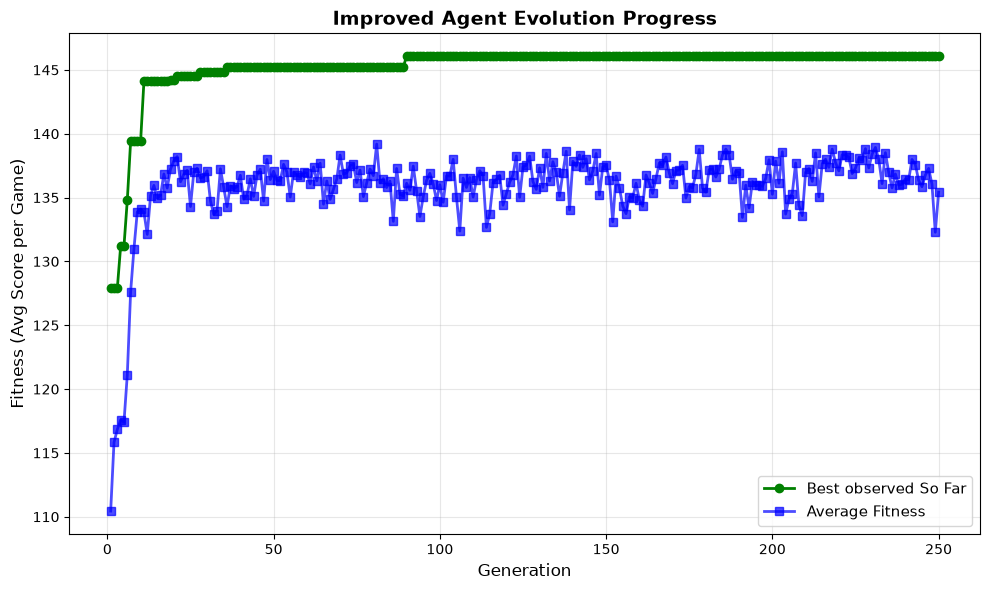


🎉 Your improved agent's final genes:
   [1.0, 1.0, 1.0, 0.43373272285164033, 0.29022285100878714, 0.0]


In [23]:
# ============================================================================
# PART 7: EVOLVE YOUR IMPROVED AGENT
# ============================================================================


print("\n" + "="*70)
print("🔧 EVOLVING YOUR IMPROVED AGENT!")
print("="*70)


def evolve_improved(generations=25, pop_size=20, opponents=None, mutation_rate=0.15, elitism=2):
    """
    Evolve using the ImprovedEvolvableAgent class
    (Same as evolve() but uses ImprovedEvolvableAgent instead of EvolvableAgent)
    """
    if opponents is None:
        opponents = opponent_pool
    
    print(f"\n🧬 EVOLUTION STARTING (Improved Agent)")
    print(f"{'='*70}")
    print(f"Population: {pop_size} | Generations: {generations} | Mutation: {mutation_rate}")
    print(f"Opponents: {len(opponents)} | Elitism: {elitism}")
    print(f"{'='*70}\n")
    
    best_fitness_history = []
    avg_fitness_history = []
    
    # Initialize population with ImprovedEvolvableAgent
    population = [ImprovedEvolvableAgent(name=f"Agent_{i}") for i in range(pop_size)]
    
    best_overall_agent = None
    best_overall_fitness = -float('inf')
    
    for gen in range(generations):
        # Evaluate fitness
        fitnesses = []
        for agent in population:
            fitness = evaluate_fitness(agent, opponents, num_rounds=50)
            fitnesses.append(fitness)
        
        # Track best
        best_fitness = max(fitnesses)
        avg_fitness = sum(fitnesses) / len(fitnesses)
        
        # Update best overall
        best_idx = fitnesses.index(best_fitness)
        if best_fitness > best_overall_fitness:
            best_overall_fitness = best_fitness
            best_overall_agent = ImprovedEvolvableAgent(genes=population[best_idx].genes.copy())
        
        best_fitness_history.append(best_overall_fitness)
        avg_fitness_history.append(avg_fitness)
        
        print(f"Gen {gen+1:3d}/{generations}: "
              f"Best={best_overall_fitness:6.2f} | Avg={avg_fitness:6.2f} | "
              f"Genes={[f'{g:.2f}' for g in population[best_idx].genes]}")
        
        # Create next generation
        if gen < generations - 1:
            sorted_indices = sorted(range(len(fitnesses)), 
                                  key=lambda i: fitnesses[i], 
                                  reverse=True)
            
            # Elitism
            next_population = []
            for i in range(elitism):
                elite_genes = population[sorted_indices[i]].genes.copy()
                next_population.append(ImprovedEvolvableAgent(genes=elite_genes))
            
            # Selection
            selected = tournament_selection(population, fitnesses)
            
            # Crossover and mutation
            while len(next_population) < pop_size:
                parent1, parent2 = random.sample(selected, 2)
                child = crossover_and_mutate(parent1, parent2, mutation_rate)
                # Convert to ImprovedEvolvableAgent
                next_population.append(ImprovedEvolvableAgent(genes=child.genes))
            
            population = next_population
    
    print(f"\n{'='*70}")
    print(f"✅ EVOLUTION COMPLETE!")
    print(f"🏆 Best fitness achieved: {best_overall_fitness:.2f}")
    print(f"{'='*70}\n")
    
    # Plot
    plt.figure(figsize=(10, 6))
    plt.plot(range(1, generations+1), best_fitness_history, 
             label='Best observed So Far', linewidth=2, color='green', marker='o')
    plt.plot(range(1, generations+1), avg_fitness_history, 
             label='Average Fitness', linewidth=2, color='blue', marker='s', alpha=0.7)
    plt.xlabel('Generation', fontsize=12)
    plt.ylabel('Fitness (Avg Score per Game)', fontsize=12)
    plt.title('Improved Agent Evolution Progress', fontsize=14, fontweight='bold')
    plt.legend(fontsize=11)
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()
    
    return best_overall_agent


# TODO: Experiment with these parameters to find the best improved agent!
my_improved_agent = evolve_improved(
    generations=250,      # Try: 20, 30, 50
    pop_size=20,         # Try: 15, 20, 30
    opponents=opponent_pool,
    mutation_rate=0.15,   # Try: 0.1, 0.15, 0.2
    elitism=2            # Keep top 2 agents each generation
)

print(f"\n🎉 Your improved agent's final genes:")
print(f"   {my_improved_agent.genes}")

In [24]:

# ============================================================================
# PART 8.1: Compare: Original vs Improved
# ============================================================================

print("\n" + "="*70)
print("📊 COMPARISON: Original vs Improved Agent")
print("="*70 + "\n")

print("ORIGINAL AGENT:")
wins_orig = 0
for opponent in opponent_pool:
    game = Game(my_evolved_agent, opponent, num_rounds=100)
    my_score, opp_score = game.play()
    if my_score > opp_score:
        wins_orig += 1
        result = "✅ WON"
    elif my_score < opp_score:
        result = "❌ LOST"
    else:
        result = "🤝 TIED"
    print(f"vs {opponent.name:25s}: {my_score:3d} - {opp_score:3d}  {result}")

print(f"\nOriginal Win Rate: {wins_orig / len(opponent_pool) * 100:.1f}%")

print("\n" + "-"*70 + "\n")

print("IMPROVED AGENT:")
wins_improved = 0
for opponent in opponent_pool:
    game = Game(my_improved_agent, opponent, num_rounds=100)
    my_score, opp_score = game.play()
    if my_score > opp_score:
        wins_improved += 1
        result = "✅ WON"
    elif my_score < opp_score:
        result = "❌ LOST"
    else:
        result = "🤝 TIED"
    print(f"vs {opponent.name:25s}: {my_score:3d} - {opp_score:3d}  {result}")

print(f"\nImproved Win Rate: {wins_improved / len(opponent_pool) * 100:.1f}%")

print("\n" + "="*70)
print(f"📈 IMPROVEMENT: +{wins_improved - wins_orig} wins")
print("="*70)


# ============================================================================
# GENERALIZATION TEST: Full Opponent Pool
# ============================================================================

print("\n" + "="*70)
print("🌍 GENERALIZATION TEST: Against ALL Possible Opponents")
print("="*70 + "\n")

print("Testing improved agent against the FULL opponent library:")
print("(including agents it was NOT trained on)\n")

wins_full = 0
losses_full = 0
ties_full = 0

for opponent in full_opponent_pool:
    game = Game(my_improved_agent, opponent, num_rounds=100)
    my_score, opp_score = game.play()
    
    if my_score > opp_score:
        result = "✅ WON"
        wins_full += 1
    elif my_score < opp_score:
        result = "❌ LOST"
        losses_full += 1
    else:
        result = "🤝 TIED"
        ties_full += 1
    
    # Mark if this was a training opponent
    trained_on = "📚" if any(opponent.name == o.name for o in opponent_pool) else "🆕"
    print(f"{trained_on} vs {opponent.name:25s}: {my_score:3d} - {opp_score:3d}  {result}")

print(f"\n📊 Results against ALL {len(full_opponent_pool)} opponents:")
print(f"   Wins: {wins_full} | Losses: {losses_full} | Ties: {ties_full}")
print(f"   Win Rate: {wins_full / len(full_opponent_pool) * 100:.1f}%")
print(f"\n💡 Legend: 📚 = Trained on this opponent | 🆕 = Never seen before")
print("="*70)


📊 COMPARISON: Original vs Improved Agent

ORIGINAL AGENT:
vs Always Invest            : 300 - 300  🤝 TIED
vs Random (0.5)             : 220 - 280  ❌ LOST
vs Random (0.3)             : 223 -  83  ✅ WON
vs Grim Trigger             : 300 - 300  🤝 TIED
vs Gradual                  : 300 - 300  🤝 TIED
vs Tit-for-Two-Tats         : 300 - 300  🤝 TIED
vs Random (0.9)             : 261 - 326  ❌ LOST
vs Generous Tit-for-Tat     : 300 - 300  🤝 TIED
vs Hard Majority            : 300 - 300  🤝 TIED
vs Always Undercut          :  97 - 112  ❌ LOST

Original Win Rate: 10.0%

----------------------------------------------------------------------

IMPROVED AGENT:
vs Always Invest            : 300 - 300  🤝 TIED
vs Random (0.5)             : 303 -  63  ✅ WON
vs Random (0.3)             : 229 -  74  ✅ WON
vs Grim Trigger             : 300 - 300  🤝 TIED
vs Gradual                  : 300 - 300  🤝 TIED
vs Tit-for-Two-Tats         : 300 - 300  🤝 TIED
vs Random (0.9)             : 396 - 111  ✅ WON
vs Generous Ti

In [25]:

# ============================================================================
# PART 8.2: Compete in your final tournament
# ============================================================================

print("\n" + "="*70)
print("🏆 FULL TOURNAMENT COMPARISON")
print("="*70 + "\n")

# Create tournament with original agent
print("Running tournament with ORIGINAL agent...")
original_tournament_agents = full_opponent_pool + [my_evolved_agent]
original_tournament = Tournament(original_tournament_agents, rounds_per_match=100, num_tournaments=1)
original_tournament.run_tournament()

# Create tournament with improved agent
print("\n" + "-"*70)
print("\nRunning tournament with IMPROVED agent...")
improved_tournament_agents = full_opponent_pool + [my_improved_agent]
improved_tournament = Tournament(improved_tournament_agents, rounds_per_match=100, num_tournaments=1)
improved_tournament.run_tournament()

# Compare rankings
print("\n" + "="*70)
print("📊 TOURNAMENT RESULTS COMPARISON")
print("="*70 + "\n")

original_rankings = original_tournament.get_rankings()
improved_rankings = improved_tournament.get_rankings()

# Find where each agent placed
original_rank = None
improved_rank = None
original_score = None
improved_score = None

for rank, (name, score) in enumerate(original_rankings, 1):
    if name == my_evolved_agent.name:
        original_rank = rank
        original_score = score

for rank, (name, score) in enumerate(improved_rankings, 1):
    if name == my_improved_agent.name:
        improved_rank = rank
        improved_score = score

print(f"ORIGINAL AGENT:")
print(f"  Rank: {original_rank} / {len(original_rankings)}")
print(f"  Total Score: {original_score:,}")
print()
print(f"IMPROVED AGENT:")
print(f"  Rank: {improved_rank} / {len(improved_rankings)}")
print(f"  Total Score: {improved_score:,}")
print()
print(f"IMPROVEMENT:")
print(f"  Rank Change: {original_rank - improved_rank} positions {'⬆️' if improved_rank < original_rank else '⬇️' if improved_rank > original_rank else '➡️'}")
print(f"  Score Change: +{improved_score - original_score:,} points ({(improved_score - original_score)/original_score*100:.1f}%)")
print("="*70)

# Show full leaderboard
print("\n🏆 IMPROVED AGENT TOURNAMENT LEADERBOARD:")
print("=" * 50)
for rank, (name, score) in enumerate(improved_rankings, 1):
    emoji = "🥇" if rank == 1 else "🥈" if rank == 2 else "🥉" if rank == 3 else "  "
    marker = " ⭐ YOUR AGENT" if name == my_improved_agent.name else ""
    print(f"{emoji} {rank:2d}. {name:25s}: {score:,} points{marker}")


🏆 FULL TOURNAMENT COMPARISON

Running tournament with ORIGINAL agent...
Running 1 tournament(s) with 19 agents...
Match 1/342: Always Invest vs Tit-for-Tat
Match 2/342: Always Invest vs Grim Trigger
Match 3/342: Always Invest vs Pavlov
Match 4/342: Always Invest vs Tit-for-Two-Tats
Match 5/342: Always Invest vs Generous Tit-for-Tat
Match 6/342: Always Invest vs Adaptive
Match 7/342: Always Invest vs Always Undercut
Match 8/342: Always Invest vs Suspicious Tit-for-Tat
Match 9/342: Always Invest vs Gradual
Match 10/342: Always Invest vs Prober
Match 11/342: Always Invest vs Hard Majority
Match 12/342: Always Invest vs Soft Majority
Match 13/342: Always Invest vs Random (0.9)
Match 14/342: Always Invest vs Random (0.7)
Match 15/342: Always Invest vs Random (0.5)
Match 16/342: Always Invest vs Random (0.3)
Match 17/342: Always Invest vs Random (0.1)
Match 18/342: Always Invest vs Evolved Agent
Match 19/342: Tit-for-Tat vs Always Invest
Match 20/342: Tit-for-Tat vs Grim Trigger
Match 21/34

In [26]:
# ============================================================================
# PART 9: Export Complete Agent as Python Module
# ============================================================================

import inspect
from datetime import datetime

def export_complete_agent(agent, student_name, generations=100, final_fitness=None):
    """
    Export agent as a complete, standalone Python module.
    This preserves BOTH genes AND decision logic so your strategy maintains
    its competitive edge in the tournament!
    
    Args:
        agent: Your evolved ImprovedEvolvableAgent
        student_name: Your name (will be used in class name, e.g., "JohnSmith")
        generations: Number of generations you evolved for
        final_fitness: Your agent's final fitness score (optional)
    
    Returns:
        filename of the exported Python file
    """
    
    # Clean up student name for valid Python class name (remove spaces, special chars)
    clean_name = ''.join(c for c in student_name if c.isalnum())
    
    # Get the actual decision logic code
    decision_code = inspect.getsource(agent.choose_action)
    
    # The source code already has proper indentation from the class,
    # so we don't need to add extra indentation
    
    # Get training opponent names if available
    try:
        opponent_names = [opp.name for opp in opponent_pool]
        opponent_info = f"Trained against: {', '.join(opponent_names[:5])}{'...' if len(opponent_names) > 5 else ''}"
    except:
        opponent_info = "Training opponents: [info not available]"
    
    # Build the complete Python module
    code = f'''#!/usr/bin/env python
"""
Tournament Agent: {agent.name}
Student: {student_name}
Generated: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}

Evolution Details:
- Generations: {generations}
- Final Fitness: {final_fitness if final_fitness else 'N/A'}
- {opponent_info}

Strategy: {agent.description}
"""

from agents import Agent, INVEST, UNDERCUT
import random


class {clean_name}Agent(Agent):
    """
    {agent.name}
    
    {agent.description}
    
    Evolved Genes: {agent.genes}
    """
    
    def __init__(self):
        # These genes were evolved through {generations} generations
        self.genes = {agent.genes}
        
        # Required for tournament compatibility
        self.student_name = "{student_name}"
        
        super().__init__(
            name="{agent.name}",
            description="{agent.description}"
        )
    
{decision_code}


# Convenience function for tournament loading
def get_agent():
    """Return an instance of this agent for tournament use"""
    return {clean_name}Agent()


if __name__ == "__main__":
    # Test that the agent can be instantiated
    agent = get_agent()
    print(f"✅ Agent loaded successfully: {{agent.name}}")
    print(f"   Genes: {{agent.genes}}")
    print(f"   Description: {{agent.description}}")
'''
    
    # Save to file
    filename = f"{clean_name.lower()}_tournament_agent.py"
    with open(filename, 'w', encoding='utf-8') as f:
        f.write(code)
    
    print("="*70)
    print("✅ COMPLETE TOURNAMENT AGENT EXPORTED!")
    print("="*70)
    print(f"📄 File: {filename}")
    print(f"🏷️  Class: {clean_name}Agent")
    print(f"🧬 Genes: {agent.genes}")
    print()
    print("📦 What's included:")
    print("   ✓ Your evolved gene values")
    print("   ✓ Your complete decision logic (choose_action method)")
    print("   ✓ All metadata and documentation")
    print()
    print("🎯 Next Steps:")
    print(f"   1. Download '{filename}' from Jupyter")
    print("   2. Submit this .py file for the Unit 6 tournament")
    print("   3. Your strategy will compete exactly as it evolved!")
    print()
    print("🧪 Test your export:")
    print(f"   from {filename[:-3]} import get_agent")
    print("   my_agent = get_agent()")
    print("="*70)
    
    return filename


# ============================================================================
# RUN THIS: Export your improved agent
# ============================================================================

print("\n" + "="*70)
print("💾 EXPORTING YOUR TOURNAMENT AGENT")
print("="*70 + "\n")

# My information
STUDENT_NAME = "Isabelle Jean"

# Agent identity and description
my_improved_agent.name = "Isabelle Sentinel"
my_improved_agent.description = (
    "Starts cooperatively, monitors recent opponent behavior, "
    "and uses evolved thresholds to defend against undercutting."
)

print(f"Agent Name: {my_improved_agent.name}")
print(f"Description: {my_improved_agent.description}")
print(f"Genes: {[f'{g:.2f}' for g in my_improved_agent.genes]}\n")

# Export the current trained agent
exported_file = export_complete_agent(
    agent=my_improved_agent,
    student_name=STUDENT_NAME,
    generations=250,
    final_fitness=146.10
)

print(f"\n✨ Export created: {exported_file}")



💾 EXPORTING YOUR TOURNAMENT AGENT

Agent Name: Isabelle Sentinel
Description: Starts cooperatively, monitors recent opponent behavior, and uses evolved thresholds to defend against undercutting.
Genes: ['1.00', '1.00', '1.00', '0.43', '0.29', '0.00']

✅ COMPLETE TOURNAMENT AGENT EXPORTED!
📄 File: isabellejean_tournament_agent.py
🏷️  Class: IsabelleJeanAgent
🧬 Genes: [1.0, 1.0, 1.0, 0.43373272285164033, 0.29022285100878714, 0.0]

📦 What's included:
   ✓ Your evolved gene values
   ✓ Your complete decision logic (choose_action method)
   ✓ All metadata and documentation

🎯 Next Steps:
   1. Download 'isabellejean_tournament_agent.py' from Jupyter
   2. Submit this .py file for the Unit 6 tournament
   3. Your strategy will compete exactly as it evolved!

🧪 Test your export:
   from isabellejean_tournament_agent import get_agent
   my_agent = get_agent()

✨ Export created: isabellejean_tournament_agent.py


## Post-Evolution Reflection Questions

### 1. Generalization Analysis
- Compare your agent's performance on training opponents (📚) vs. unseen opponents (🆕)
- Did your agent generalize well or overfit to the training set?
- What does this suggest about evolving against a random sample vs. fixed opponents?

In the full-pool benchmark, my agent earned 3 wins, 1 loss, and 6 ties against its 10 training opponents, compared with 3 wins and 5 ties against the eight unseen opponents, including wins against unseen Random (0.7), Random (0.1), and Prober. It generalized reasonably well in this test rather than succeeding only against its training opponents, but its 103–103 tie against Suspicious Tit-for-Tat shows that handling an unfamiliar opponent without losing does not necessarily produce strong earnings. A random training sample can introduce varied strategies, but one sample can still leave important behaviors out; a fixed pool makes experiments easier to compare but can encourage specialization, so I would keep the pool fixed during tuning and use excluded opponents to assess how well the strategy transfers.

### 2. Tournament Performance
- What was your agent's final tournament rank? 4 out of 19
- What was your agent's total score? 4730
- Look at agents that ranked above and below you - what strategies do they use?

My Isabelle Sentinel agent earned 4,730 points, improving on my original agent’s 4,578 points and eighth-place finish. Above it, Gradual scored 4,893 by using escalating punishment after betrayals, Grim Trigger scored 4,798 with permanent retaliation after an undercut, and Hard Majority scored 4,738 by undercutting when more than half of the opponent’s past actions were undercuts. Immediately below mine, Generous Tit-for-Tat scored 4,717 by generally copying the opponent’s previous action while occasionally forgiving undercuts, and Tit-for-Tat scored 4,695 by directly matching the previous action; my agent’s seven-action memory could sustain retaliation longer, and its placement, just eight points behind third and thirteen ahead of fifth, suggests that this defensive approach was competitive in this run, although the narrow margins do not establish a consistent advantage.

### 3. Strategy Analysis
Look at your evolved genes: [1.0, 1.0, 1.0, 0.43373272285164033, 0.29022285100878714, 0.0]

- In plain English, what strategy did your agent evolve?
- Does it cooperate with cooperators? Does it punish defectors?
- Why do you think evolution discovered this particular strategy?

My agent evolved a cooperative opening followed by strict retaliation: it invests first and continues cooperating while its recent memory contains no undercuts. Its seven-action memory and 10% retaliation threshold mean that even one remembered undercut activates certain retaliation, so the forgiveness gene has no practical effect with this particular combination of settings. Evolution likely favored this strategy because it preserves mutual investment with cooperative opponents while collecting points from random opponents that continue investing even after my agent becomes defensive.

### 4. Trade-offs
Every strategy has strengths and weaknesses.

- Which types of opponents does your agent beat?
- Which types beat your agent?
- If you could redesign your agent for Unit 6, what would you change?

In the full-pool benchmark, my agent beat all five Random agents and Prober, while its only loss was 99–104 against Always Undercut because it gave away an advantage on the opening round. Its strength is limiting repeated exploitation, but the 103–103 tie against Suspicious Tit-for-Tat and 107–102 win against Prober expose a weakness in rebuilding cooperation after conflict. For Unit 6, I would add an evolved rule for occasionally attempting cooperation after prolonged mutual undercutting, then use the opponent’s response to decide whether to continue or return to defense.
### 5. The Environment Matters
- You evolved against a random sample of 10 opponents
- The tournament included all 19 opponents
- Unit 6 will include 30+ student agents with unpredictable strategies
- How might your agent perform in that different environment?

My agent trained against 10 sampled opponents, and the final tournament contained 19 agents: my agent plus the full library of 18 opponents. Its fourth-place finish is encouraging, but 30-plus student agents could introduce delayed betrayal, changing behavior, or attempts to exploit its predictable retaliation, so success in this environment does not guarantee the same placement in Unit 6. I would prepare by evolving against a broader mix of behaviors and evaluating separate opponents across different match lengths and noise levels, because an effective adaptive system needs to perform beyond the conditions that produced its highest training score.